In [ ]:
import pandas as pd
import matplotlib as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

In [27]:
df = pd.read_csv(r"C:\Users\Sobiya Ayaz\OneDrive\Desktop\Solubility Project\solubility_with_descriptors.csv")
df

,MolLogP,MolWt,NumRotatableBonds,AromaticProportion,logS
0,2.59540,167.850,0.0,0.000000,-2.180
1,2.37650,133.405,0.0,0.000000,-2.000
2,2.59380,167.850,1.0,0.000000,-1.740
3,2.02890,133.405,1.0,0.000000,-1.480
4,2.91890,187.375,1.0,0.000000,-3.040
...,...,...,...,...,...
1139,1.98820,287.343,8.0,0.000000,1.144
1140,3.42130,286.114,2.0,0.333333,-4.925
1141,3.60960,308.333,4.0,0.695652,-3.893
1142,2.56214,354.815,3.0,0.521739,-3.790


In [28]:
df.head()

,MolLogP,MolWt,NumRotatableBonds,AromaticProportion,logS
0,2.5954,167.850,0.0,0.0,-2.18
1,2.3765,133.405,0.0,0.0,-2.00
2,2.5938,167.850,1.0,0.0,-1.74
3,2.0289,133.405,1.0,0.0,-1.48
4,2.9189,187.375,1.0,0.0,-3.04


In [29]:
df.drop_duplicates(inplace = True)

In [30]:
df.duplicated().sum()

np.int64(0)

In [31]:
df.isnull().sum()

MolLogP               0
MolWt                 0
NumRotatableBonds     0
AromaticProportion    0
logS                  0
dtype: int64

In [32]:
df.dtypes

MolLogP               float64
MolWt                 float64
NumRotatableBonds     float64
AromaticProportion    float64
logS                  float64
dtype: object

In [33]:
df.describe()

,MolLogP,MolWt,NumRotatableBonds,AromaticProportion,logS
count,1129.000000,1129.000000,1129.000000,1129.000000,1129.000000
mean,2.448913,204.653439,2.175376,0.363141,-3.061477
std,1.867872,102.533078,2.631855,0.343093,2.090722
min,-7.571400,16.043000,0.000000,0.000000,-11.600000
25%,1.414900,122.127000,0.000000,0.000000,-4.328000
50%,2.348600,183.169000,1.000000,0.375000,-2.890000
75%,3.402200,270.372000,3.000000,0.666667,-1.600000
max,10.388600,780.949000,23.000000,1.000000,1.580000


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1129 entries, 0 to 1143
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   MolLogP             1129 non-null   float64
 1   MolWt               1129 non-null   float64
 2   NumRotatableBonds   1129 non-null   float64
 3   AromaticProportion  1129 non-null   float64
 4   logS                1129 non-null   float64
dtypes: float64(5)
memory usage: 52.9 KB


In [35]:
X = df.drop('logS', axis = 1)
y = df['logS']

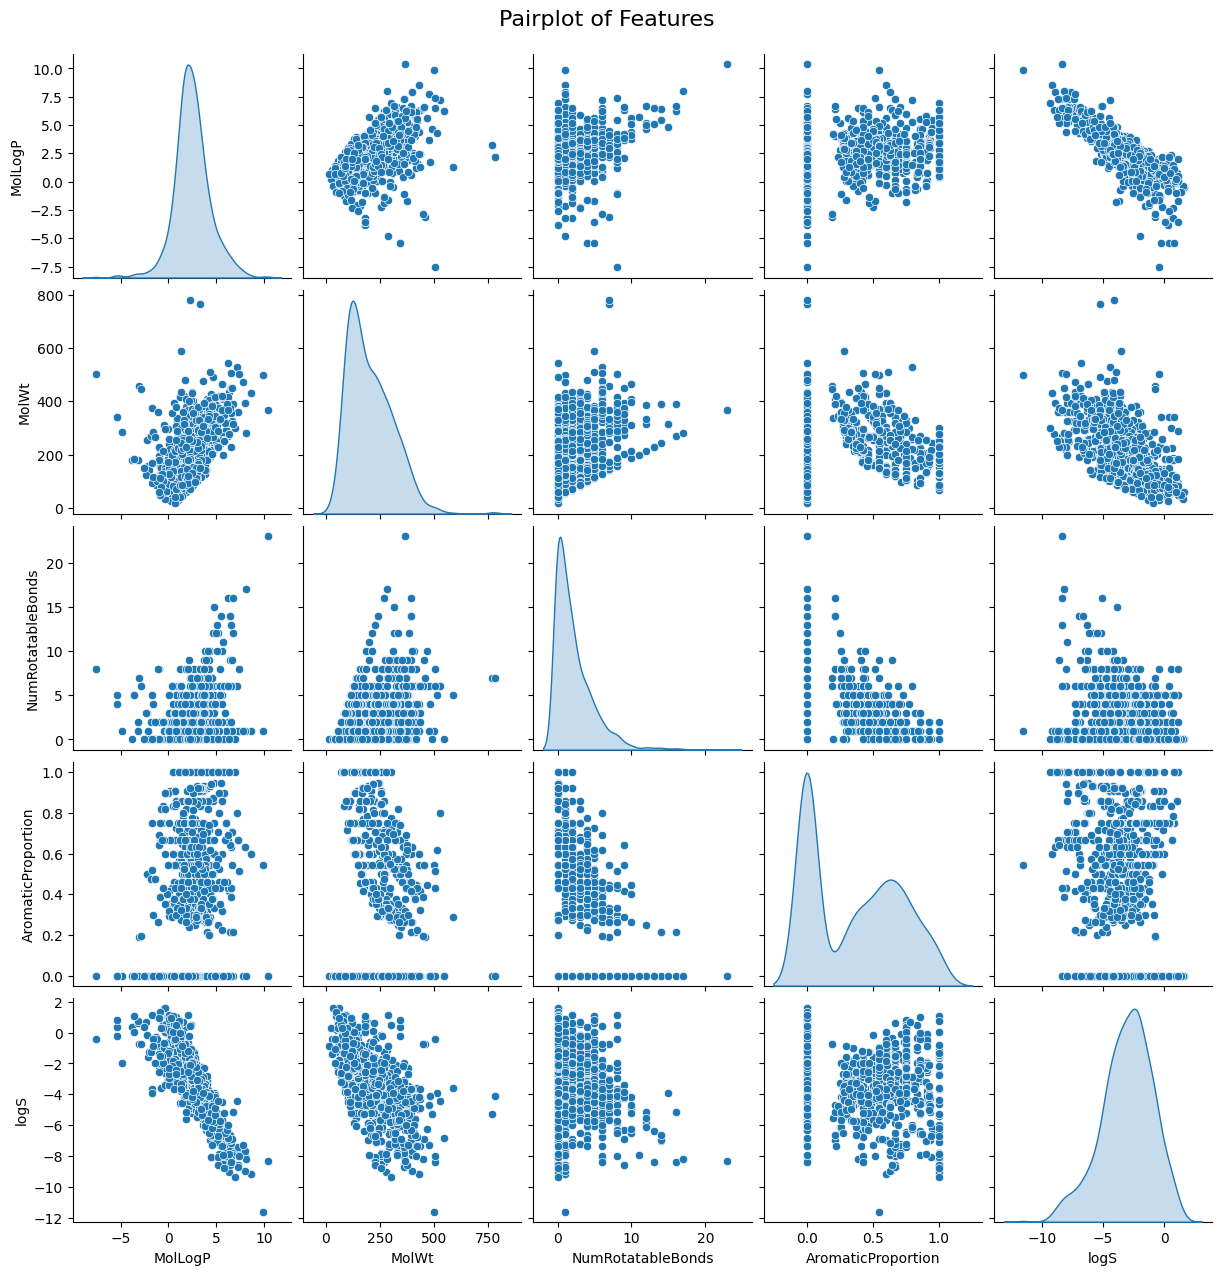

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df, diag_kind="kde")
plt.suptitle("Pairplot of Features", y=1.02, fontsize=16)
plt.show()

# histogram showing mass, weight, polarity and hydrophobicity
# scatter plot indicating the relation between molwt vs logP (heavier mol are more hydrophobic)
# numRings vs molwt ( more rings heavier the molecule)
# polSurfaceArea vs logP ( more polar less hydrophobic)

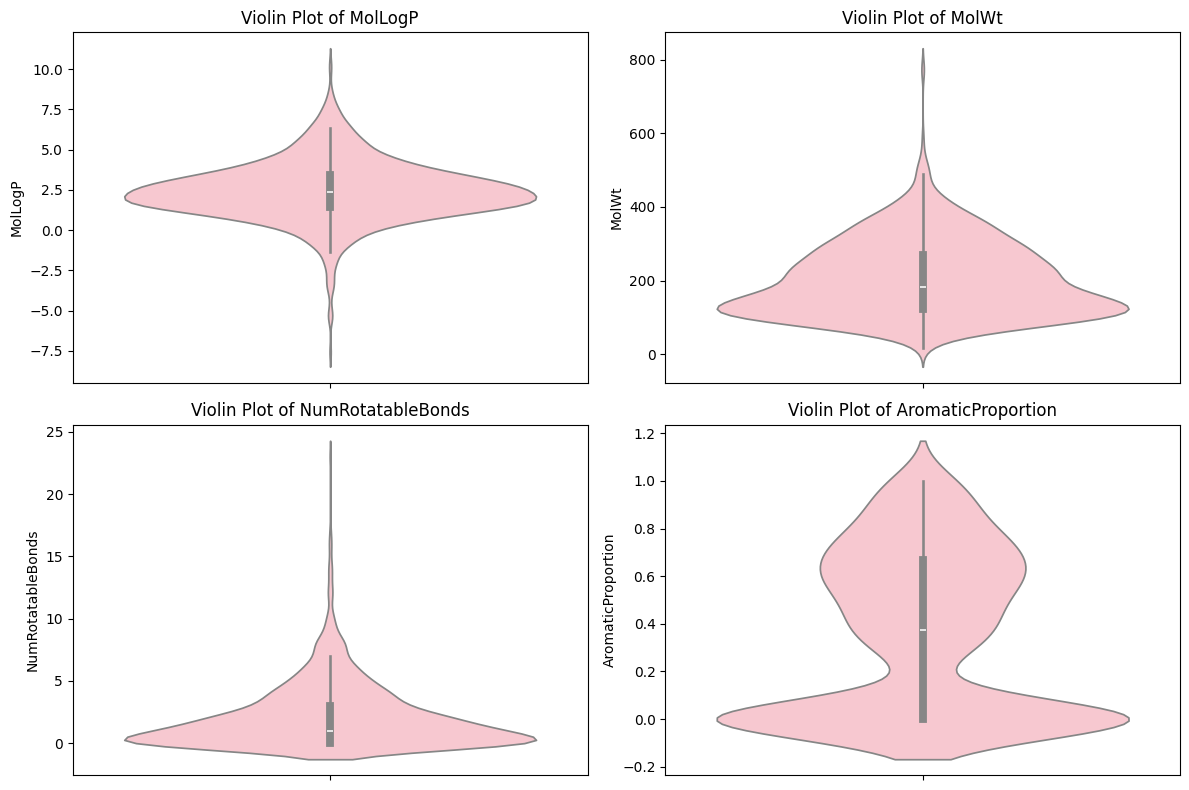

In [37]:
plt.figure(figsize=(12, 8))
for i, col in enumerate(df.columns[:-1], 1):  # skip logS since it's target
    plt.subplot(2, 2, i)
    sns.violinplot(y=df[col] , color= 'pink')
    plt.title(f"Violin Plot of {col}")
plt.tight_layout()
plt.show()


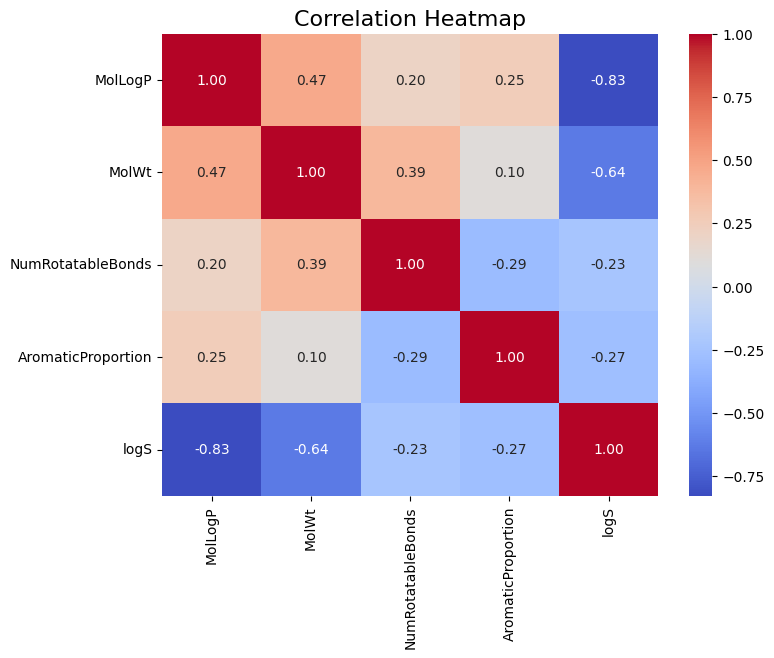

In [38]:
# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap", fontsize=16)
plt.show()

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 100)

In [40]:
# Linear Regression

from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [41]:
y_lr_train_pred = lr.predict(X_train)
y_lr_test_pred = lr.predict(X_test)

In [42]:
from sklearn.metrics import mean_squared_error, r2_score

lr_train_mse = mean_squared_error(y_train, y_lr_train_pred)
lr_train_r2 = r2_score(y_train, y_lr_train_pred)

lr_test_mse = mean_squared_error(y_test, y_lr_test_pred)
lr_test_r2 = r2_score(y_test, y_lr_test_pred)

In [43]:
print(lr_train_mse)
print(lr_train_r2)
print(lr_test_mse)
print(lr_test_r2)

1.0234262732248198
0.7618733745069931
0.9462765670587434
0.7961306669681304


In [44]:
lr_results = pd.DataFrame(['Linear regression',lr_train_mse, lr_train_r2, lr_test_mse, lr_test_r2]).transpose()
lr_results.columns = ['Method', 'Training mse', 'Training r2', 'Test mse', 'Test r2']
lr_results

,Method,Training mse,Training r2,Test mse,Test r2
0,Linear regression,1.023426,0.761873,0.946277,0.796131


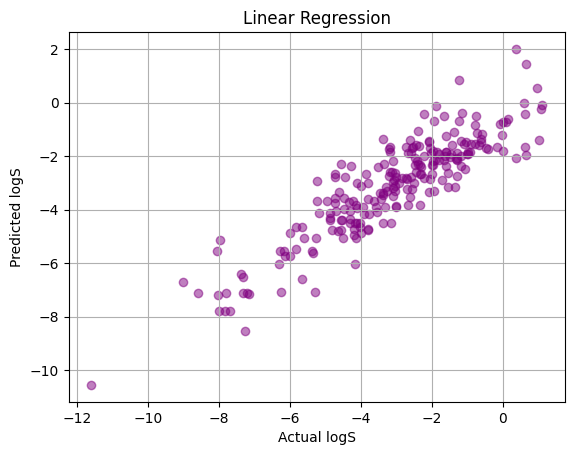

In [45]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_lr_test_pred, alpha=0.5, color='purple')
plt.xlabel("Actual logS")
plt.ylabel("Predicted logS")
plt.title("Linear Regression")
plt.grid(True)
plt.show()


In [46]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor()
rf.fit(X_train, y_train)



,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [47]:
y_rf_train_pred = rf.predict(X_train)
y_rf_test_pred = rf.predict(X_test)
y_rf_test_pred

array([ 0.9627    , -2.25752833, -1.56966   , -3.95195   , -3.96395333,
       -7.57290278, -4.053216  , -1.44657988, -3.11040667, -1.87229667,
       -0.510935  , -3.20296333, -3.18853833,  0.44776   , -4.37352   ,
       -4.43982617, -2.06985667, -2.3227    , -7.90306956, -5.86475   ,
       -3.27209667,  0.7196    , -1.12789   , -7.2955561 , -2.25752833,
       -6.62109017, -3.37295167, -1.84977   , -4.28051517, -1.3552275 ,
       -0.37290833, -2.31727524, -4.89049667, -2.31706333, -3.31705   ,
       -4.053216  , -2.6897419 , -4.64774643, -4.01152   , -2.49178333,
       -2.0828    , -3.50960095, -2.29914778, -5.9990769 , -6.28433675,
        0.31188667, -2.52071   , -4.51597   , -4.590575  , -0.92426917,
       -2.63573   , -1.69267167, -0.63466917, -1.96546333, -0.03908333,
       -1.82001   , -5.86475   , -2.6709    ,  0.49396   , -1.94315333,
        0.55882   , -5.84208   , -4.18157333, -1.67259667, -0.93597167,
       -3.86145   , -0.73257075, -4.09421867, -2.36823   , -1.58

In [48]:
from sklearn.metrics import mean_squared_error, r2_score

rf_train_mse = mean_squared_error(y_train, y_rf_train_pred)
rf_train_r2 = r2_score(y_train, y_rf_train_pred)

rf_test_mse = mean_squared_error(y_test, y_rf_test_pred)
rf_test_r2 = r2_score(y_test, y_rf_test_pred)

In [49]:
rf_results = pd.DataFrame(['Random Forest',rf_train_mse, rf_train_r2, lr_test_mse, rf_test_r2]).transpose()
rf_results.columns = ['Method', 'Training mse', 'Training r2', 'Test mse', 'Test r2']
rf_results

,Method,Training mse,Training r2,Test mse,Test r2
0,Random Forest,0.094896,0.97792,0.946277,0.892997


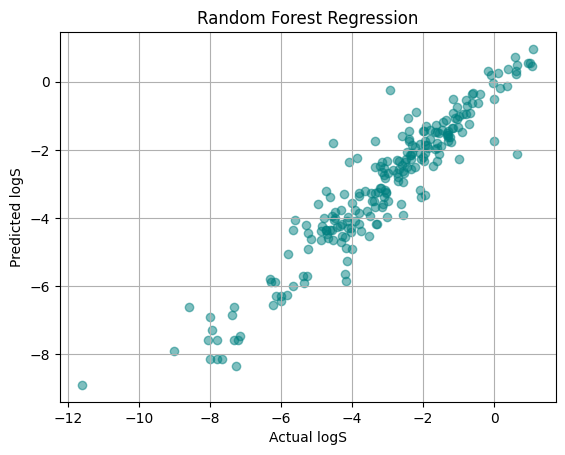

In [50]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_rf_test_pred, alpha=0.5, color='teal')
plt.xlabel("Actual logS")
plt.ylabel("Predicted logS")
plt.title("Random Forest Regression")
plt.grid(True)
plt.show()

In [51]:
df_models = pd.concat([lr_results, rf_results], axis = 0)
df_models

,Method,Training mse,Training r2,Test mse,Test r2
0,Linear regression,1.023426,0.761873,0.946277,0.796131
0,Random Forest,0.094896,0.97792,0.946277,0.892997


In [52]:
df_models.reset_index(drop=True)

,Method,Training mse,Training r2,Test mse,Test r2
0,Linear regression,1.023426,0.761873,0.946277,0.796131
1,Random Forest,0.094896,0.97792,0.946277,0.892997


In [53]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

In [54]:
from sklearn.metrics import mean_squared_error, r2_score

mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print(mse_dt)
print(r2_dt)


0.8473210022431171
0.8174500208452525


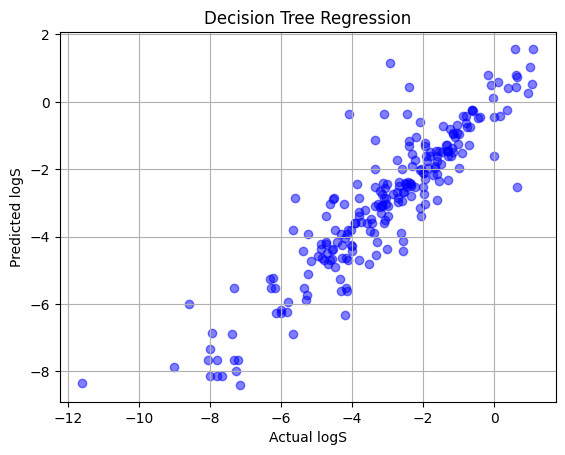

In [55]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_dt, alpha=0.5, color='blue')
plt.xlabel("Actual logS")
plt.ylabel("Predicted logS")
plt.title("Decision Tree Regression")
plt.grid(True)
plt.show()


In [56]:
from sklearn.svm import SVR

svm = SVR()
svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)


In [57]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


from sklearn.metrics import mean_squared_error, r2_score

mse_svm = mean_squared_error(y_test, y_pred_svm)
r2_svm = r2_score(y_test, y_pred_svm)

print(mse_svm)
print(r2_svm)


2.428165729288383
0.47686697002385414


In [58]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer

svm_pipeline = make_pipeline(StandardScaler(), SVR())

scoring = {
    'mse': make_scorer(mean_squared_error),
    'r2': make_scorer(r2_score)
}

cv_results = cross_validate(svm_pipeline, X_train, y_train, cv=5, scoring=scoring)

print("Cross-validated MSE:", cv_results['test_mse'].mean())
print("Cross-validated R²:", cv_results['test_r2'].mean())


Cross-validated MSE: 0.6824391475278785
Cross-validated R²: 0.840172696053379


In [59]:
df

,MolLogP,MolWt,NumRotatableBonds,AromaticProportion,logS
0,2.59540,167.850,0.0,0.000000,-2.180
1,2.37650,133.405,0.0,0.000000,-2.000
2,2.59380,167.850,1.0,0.000000,-1.740
3,2.02890,133.405,1.0,0.000000,-1.480
4,2.91890,187.375,1.0,0.000000,-3.040
...,...,...,...,...,...
1139,1.98820,287.343,8.0,0.000000,1.144
1140,3.42130,286.114,2.0,0.333333,-4.925
1141,3.60960,308.333,4.0,0.695652,-3.893
1142,2.56214,354.815,3.0,0.521739,-3.790


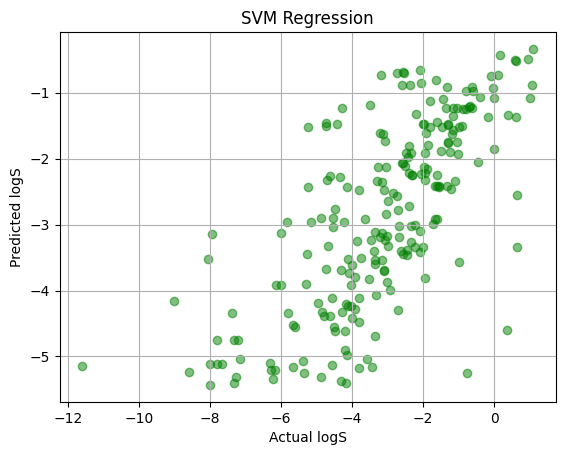

In [60]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_svm, alpha=0.5, color='green')
plt.xlabel("Actual logS")
plt.ylabel("Predicted logS")
plt.title("SVM Regression")
plt.grid(True)
plt.show()


In [61]:
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)


In [62]:
mse_knn = mean_squared_error(y_test, y_pred_knn)
r2_knn = r2_score(y_test, y_pred_knn)

print( mse_knn)
print(r2_knn)


1.5788052513274335
0.6598563413909879


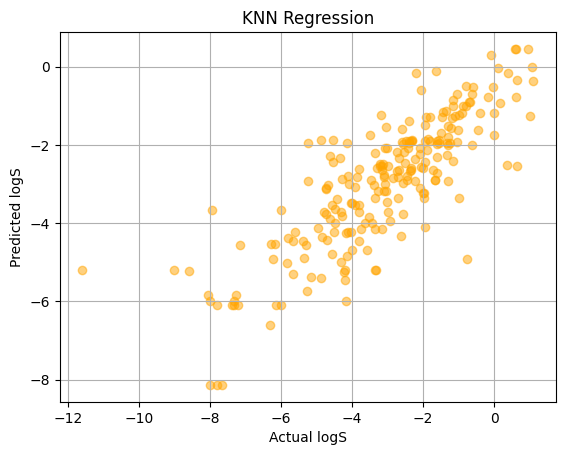

In [63]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_knn, alpha=0.5, color='orange')
plt.xlabel("Actual logS")
plt.ylabel("Predicted logS")
plt.title("KNN Regression")
plt.grid(True)
plt.show()


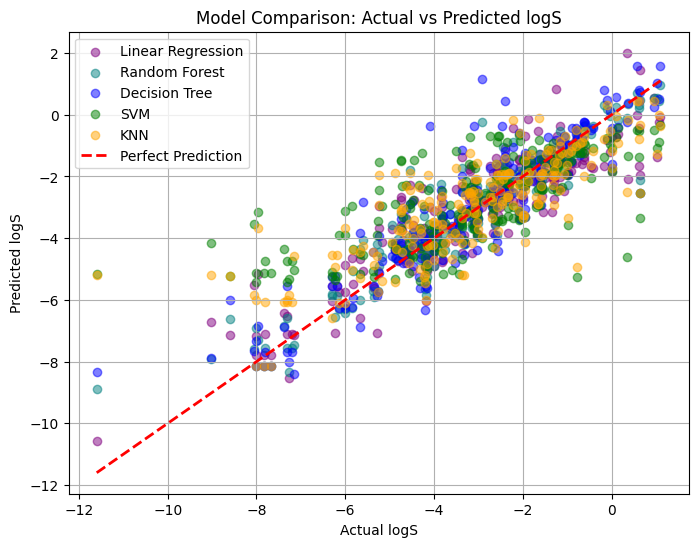

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

# Plot predictions from each model
plt.scatter(y_test, y_lr_test_pred, alpha=0.5, color='purple', label="Linear Regression")
plt.scatter(y_test, y_rf_test_pred, alpha=0.5, color='teal', label="Random Forest")
plt.scatter(y_test, y_pred_dt, alpha=0.5, color='blue', label="Decision Tree")
plt.scatter(y_test, y_pred_svm, alpha=0.5, color='green', label="SVM")
plt.scatter(y_test, y_pred_knn, alpha=0.5, color='orange', label="KNN")

# Perfect prediction reference line
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Perfect Prediction")

# Labels & formatting
plt.xlabel("Actual logS")
plt.ylabel("Predicted logS")
plt.title("Model Comparison: Actual vs Predicted logS")
plt.legend()
plt.grid(True)
plt.show()